# 04 — Classification EDA with development data only

The class definition comes from the published training-only rule. This analysis does not load test outcomes. The original notebook remains unchanged.


In [1]:
USE_COLUMNS = ["split", "target_week", "sales", "target_high_demand"]
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/process_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from fashion-demand-ml.")
sys.path.insert(0, str(ROOT))
from src.visualization.style import apply_style, add_title, add_source, display_es
apply_style()
processed = ROOT / "data/processed"
pointer = json.loads((processed / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json must select a complete publication.")
summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
dataset_path = run_dir / "article_week.csv.gz"
parts = []
for chunk in pd.read_csv(dataset_path, usecols=USE_COLUMNS,
                         parse_dates=["target_week"], chunksize=250_000):
    part = chunk.loc[chunk["split"].isin(["train", "validation"])]
    if len(part):
        parts.append(part)
data = pd.concat(parts, ignore_index=True)
assert set(data["split"]) == {"train", "validation"}
print("Development rows:", len(data))
print("Test rows loaded into the analysis:", 0)


Development rows: 1597649
Test rows loaded into the analysis: 0


,rows,high_demand_share
split,,
train,1.326.434,"0,199"
validation,271.215,"0,213"


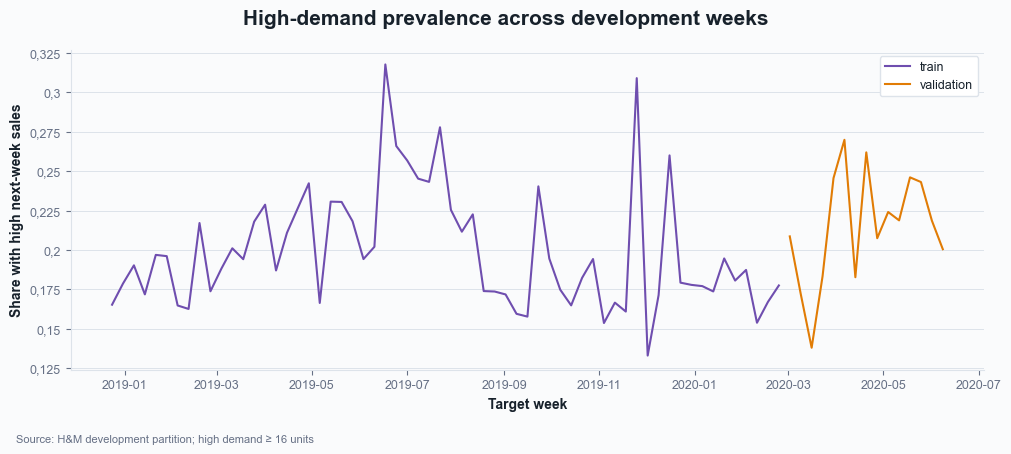

In [2]:
train = data.loc[data["split"].eq("train")].copy()
threshold_units = int(summary["classification_target"]["threshold_units"])
assert data["target_high_demand"].isin([0, 1]).all()
prevalence = data.groupby("split")["target_high_demand"].agg(["size", "mean"])
display_es(prevalence.rename(columns={"size": "rows", "mean": "high_demand_share"}))
weekly = data.groupby(["split", "target_week"])["target_high_demand"].mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
for split, color in [("train", "#6F4EAF"), ("validation", "#E17C05")]:
    subset = weekly.loc[weekly["split"].eq(split)]
    ax.plot(subset["target_week"], subset["target_high_demand"], color=color, label=split)
add_title(fig, "High-demand prevalence across development weeks")
ax.set_xlabel("Target week", fontweight="bold")
ax.set_ylabel("Share with high next-week sales", fontweight="bold")
ax.grid(axis="y", color="#DDE3EA", linewidth=.7)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
add_source(fig, f"Source: H&M development partition; high demand ≥ {threshold_units} units")
plt.show()


Choose and document the probability-threshold policy using development folds. Do not use final test outcomes for this choice.
